In [1]:
# Import libraries (remember these from Weeks 1 and 2)
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing # the data is inside the library so we can easily import it and then call it later to get the data
from sklearn.linear_model import SGDRegressor, LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from mpl_toolkits.mplot3d import Axes3D

# PyTorch for optimizers comparison .. PyTorch is one of the most important frameworks that we will use
import torch
import torch.nn as nn
import torch.optim as optim

plt.style.use('dark_background') # Dark theme


print("All libraries loaded successfully!")
print(f"NumPy version: {np.__version__}")
print(f"PyTorch version: {torch.__version__}")

All libraries loaded successfully!
NumPy version: 2.1.3
PyTorch version: 2.11.0+cpu


In [2]:
# Load the California Housing dataset
california = fetch_california_housing()

# Extract features (X) and target (y)
X = california.data
y = california.target

# Get feature names
feature_names = california.feature_names

print("Dataset loaded successfully!")
print(f"\nNumber of samples: {X.shape[0]:,}")
print(f"Number of features: {X.shape[1]}")
print(f"\nFeature descriptions:")
print(f"  0: MedInc      - Median income in block group (in $10,000s)")
print(f"  1: HouseAge    - Median house age in block group (in years)")
print(f"  2: AveRooms    - Average number of rooms per household")
print(f"  3: AveBedrms   - Average number of bedrooms per household")
print(f"  4: Population  - Block group population")
print(f"  5: AveOccup    - Average number of household members")
print(f"  6: Latitude    - Block group latitude")
print(f"  7: Longitude   - Block group longitude")
print(f"\nTarget: Median house value (in $100,000s)")
print(f"\nExample: MedInc=3.5 means median income is $35,000")

Dataset loaded successfully!

Number of samples: 20,640
Number of features: 8

Feature descriptions:
  0: MedInc      - Median income in block group (in $10,000s)
  1: HouseAge    - Median house age in block group (in years)
  2: AveRooms    - Average number of rooms per household
  3: AveBedrms   - Average number of bedrooms per household
  4: Population  - Block group population
  5: AveOccup    - Average number of household members
  6: Latitude    - Block group latitude
  7: Longitude   - Block group longitude

Target: Median house value (in $100,000s)

Example: MedInc=3.5 means median income is $35,000


In [3]:
# Let's look at the first 5 samples
print("First 5 houses:\n")
for i in range(5):
    print(f"House {i+1}:")
    for j, name in enumerate(feature_names):
        print(f"  {name}: {X[i, j]:.2f}")
    print(f"  → Price: ${y[i]*100000:,.0f}")
    print()

First 5 houses:

House 1:
  MedInc: 8.33
  HouseAge: 41.00
  AveRooms: 6.98
  AveBedrms: 1.02
  Population: 322.00
  AveOccup: 2.56
  Latitude: 37.88
  Longitude: -122.23
  → Price: $452,600

House 2:
  MedInc: 8.30
  HouseAge: 21.00
  AveRooms: 6.24
  AveBedrms: 0.97
  Population: 2401.00
  AveOccup: 2.11
  Latitude: 37.86
  Longitude: -122.22
  → Price: $358,500

House 3:
  MedInc: 7.26
  HouseAge: 52.00
  AveRooms: 8.29
  AveBedrms: 1.07
  Population: 496.00
  AveOccup: 2.80
  Latitude: 37.85
  Longitude: -122.24
  → Price: $352,100

House 4:
  MedInc: 5.64
  HouseAge: 52.00
  AveRooms: 5.82
  AveBedrms: 1.07
  Population: 558.00
  AveOccup: 2.55
  Latitude: 37.85
  Longitude: -122.25
  → Price: $341,300

House 5:
  MedInc: 3.85
  HouseAge: 52.00
  AveRooms: 6.28
  AveBedrms: 1.08
  Population: 565.00
  AveOccup: 2.18
  Latitude: 37.85
  Longitude: -122.25
  → Price: $342,200



In [4]:
# Basic statistics (using Week 2 knowledge!)
print("Feature Statistics:\n")
print(f"{'Feature':<15} {'Mean':<12} {'Std':<12} {'Min':<12} {'Max':<12}") # < is just for spacing so don't worry about this .. this is just for visualising this to look like a table
print("="*63)
for i, name in enumerate(feature_names):
    print(f"{name:<15} {np.mean(X[:, i]):<12.2f} {np.std(X[:, i]):<12.2f} "
          f"{np.min(X[:, i]):<12.2f} {np.max(X[:, i]):<12.2f}")

print(f"\n{'Target (Price)':<15} {np.mean(y):<12.2f} {np.std(y):<12.2f} "
      f"{np.min(y):<12.2f} {np.max(y):<12.2f}")

Feature Statistics:

Feature         Mean         Std          Min          Max         
MedInc          3.87         1.90         0.50         15.00       
HouseAge        28.64        12.59        1.00         52.00       
AveRooms        5.43         2.47         0.85         141.91      
AveBedrms       1.10         0.47         0.33         34.07       
Population      1425.48      1132.43      3.00         35682.00    
AveOccup        3.07         10.39        0.69         1243.33     
Latitude        35.63        2.14         32.54        41.95       
Longitude       -119.57      2.00         -124.35      -114.31     

Target (Price)  2.07         1.15         0.15         5.00        


In [5]:
# Calculate correlation of each feature with target
correlations = []
for i in range(X.shape[1]):
    # Correlation formula: cov(X, y) / (std(X) * std(y))  ... remember that correlation is just normalised covariance
    corr = np.corrcoef(X[:, i], y)[0, 1] # we can call this function to get the correlation directly
    correlations.append(corr)

# Sort by absolute correlation
sorted_indices = np.argsort(np.abs(correlations))[::-1] # because for predicting the price we don't really care if the correlation
# is positive or negative but about the strength of the correlation, remember in the simulation of the first lecture
# when points where close to the regression line and in the positive direction this increased the correlation coefficient value
# so this is what we want here.

print("Features ranked by correlation with Price:\n")
print(f"{'Rank':<6} {'Feature':<15} {'Correlation':<12}")
print("="*35)
for rank, idx in enumerate(sorted_indices, 1): # start the counter from 1
    print(f"{rank:<6} {feature_names[idx]:<15} {correlations[idx]:>+11.3f}")

print(f"\nKey Insight: {feature_names[sorted_indices[0]]} has the strongest correlation!")

Features ranked by correlation with Price:

Rank   Feature         Correlation 
1      MedInc               +0.688
2      AveRooms             +0.152
3      Latitude             -0.144
4      HouseAge             +0.106
5      AveBedrms            -0.047
6      Longitude            -0.046
7      Population           -0.025
8      AveOccup             -0.024

Key Insight: MedInc has the strongest correlation!


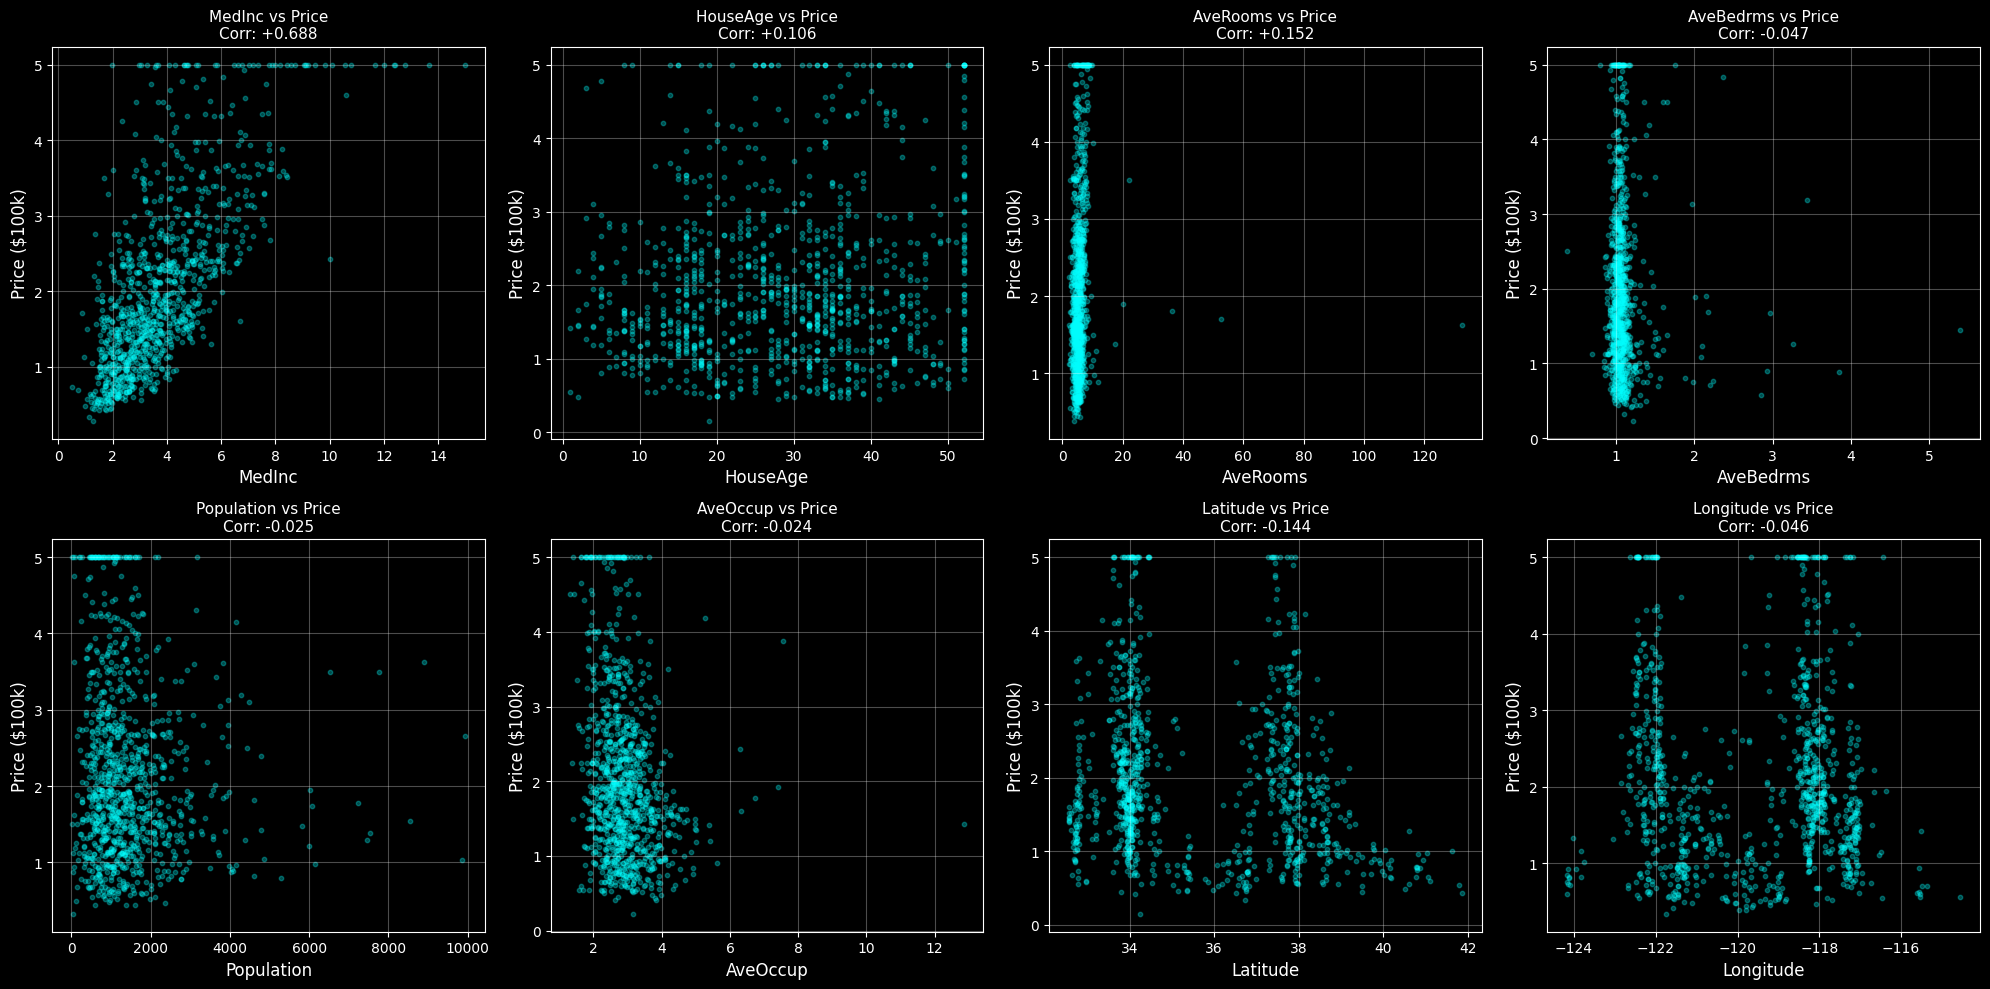

Notice how MedInc (median income) shows the clearest positive correlation .. also notice how things are looking different when dealing with real data!


In [6]:
# Visualize all features vs target
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

for i, (ax, name) in enumerate(zip(axes, feature_names)):
    # Sample 1000 points for cleaner visualization
    indices = np.random.choice(X.shape[0], 1000, replace=False)

    ax.scatter(X[indices, i], y[indices], alpha=0.3, s=10, c='cyan')
    ax.set_xlabel(name, fontsize=12)
    ax.set_ylabel('Price ($100k)', fontsize=12)
    ax.set_title(f'{name} vs Price\nCorr: {correlations[i]:+.3f}', fontsize=11)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Notice how MedInc (median income) shows the clearest positive correlation .. also notice how things are looking different when dealing with real data!")

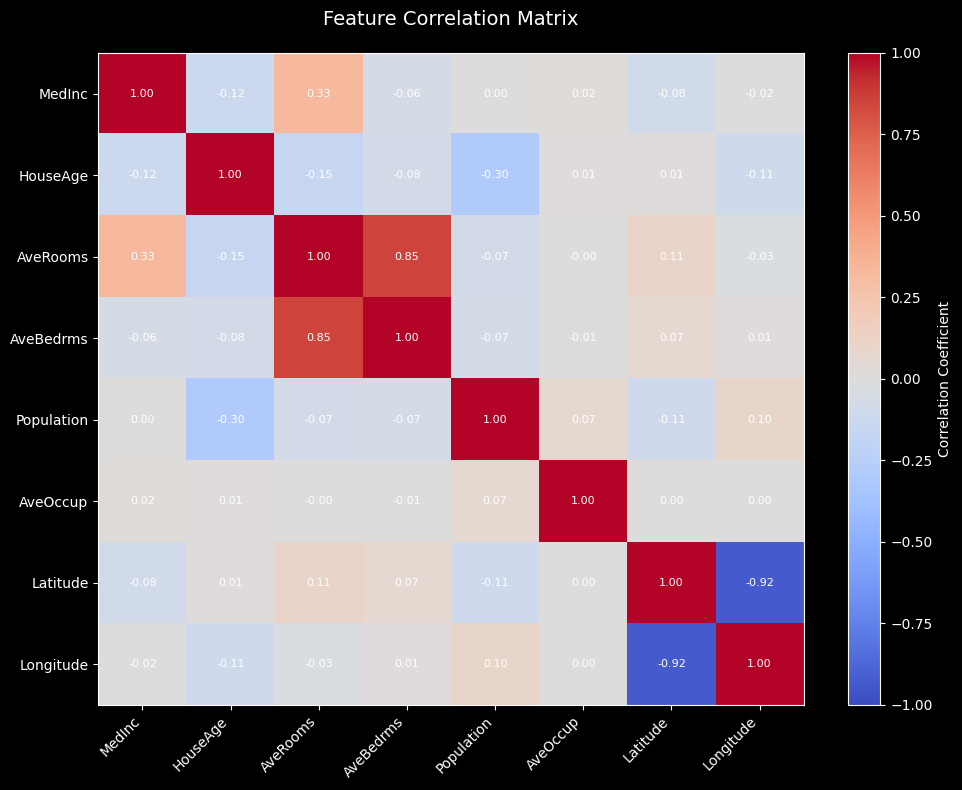


This helps us understand multicollinearity (covered in Lecture 7 but we briefly mentioned it in the first lecture 
 see how AveBedrms and AveRooms are correlated)


In [7]:
# Correlation matrix heatmap
# Calculate correlation between all features
correlation_matrix = np.corrcoef(X.T)

plt.figure(figsize=(10, 8))
plt.imshow(correlation_matrix, cmap='coolwarm', vmin=-1, vmax=1, aspect='auto')
plt.colorbar(label='Correlation Coefficient')
plt.xticks(range(len(feature_names)), feature_names, rotation=45, ha='right')
plt.yticks(range(len(feature_names)), feature_names)
plt.title('Feature Correlation Matrix', fontsize=14, pad=20)

# Add correlation values
for i in range(len(feature_names)):
    for j in range(len(feature_names)):
        plt.text(j, i, f'{correlation_matrix[i, j]:.2f}',
                ha='center', va='center', fontsize=8)

plt.tight_layout()
plt.show()

print("\nThis helps us understand multicollinearity (covered in Lecture 7 but we briefly mentioned it in the first lecture \n see how AveBedrms and AveRooms are correlated)")

##Exercise 1: Linear Regression with a Different Feature

In [10]:
# Extract HouseAge feature
x_houseage = X[:, 1]
y_price_ex1 = y

np.random.seed(42)

w_ex1 = np.random.rand()
b_ex1 = np.random.rand()
learning_rate_ex1 = 0.001
epochs_ex1 = 500
cost_history_ex1 = []

# Gradient Descent
for epoch in range(epochs_ex1):
    y_pred = (w_ex1 * x_houseage) + b_ex1
    error = y_pred - y_price_ex1

    grad_w = np.mean(error * x_houseage)
    grad_b = np.mean(error)

    w_ex1 -= learning_rate_ex1 * grad_w
    b_ex1 -= learning_rate_ex1 * grad_b

    cost = 0.5 * np.mean(error ** 2)
    cost_history_ex1.append(cost)



print(f"Final w: {w_ex1:.4f}")
print(f"Final b: {b_ex1:.4f}")
print(f"Final MSE: {cost_history_ex1[-1]:.4f}")


Final w: 0.0326
Final b: 1.0068
Final MSE: 0.7082


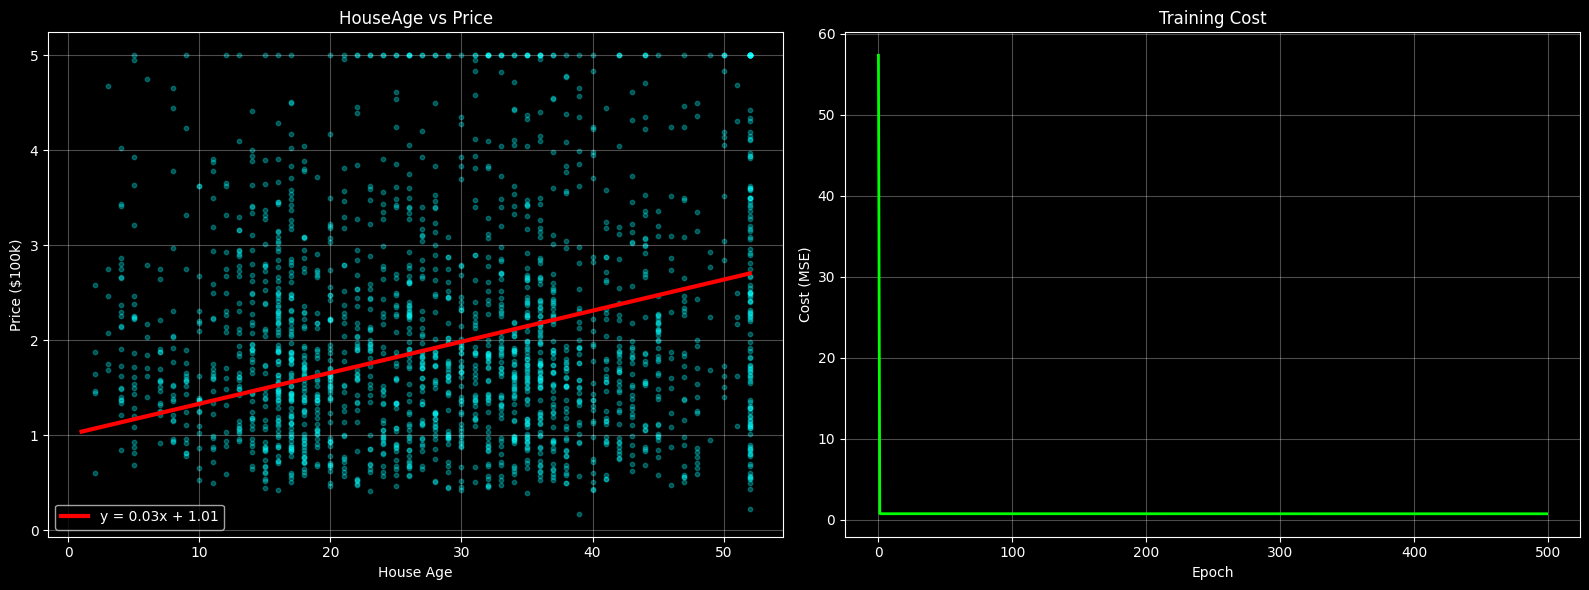


HouseAge has correlation 0.106 with price.
Compare this to MedInc's correlation of 0.688!


In [11]:
# Visualize your results
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Scatter + fitted line
indices = np.random.choice(len(x_houseage), 2000, replace=False)
axes[0].scatter(x_houseage[indices], y_price_ex1[indices], alpha=0.3, s=10, c='cyan')
x_line = np.linspace(x_houseage.min(), x_houseage.max(), 100)
y_line = w_ex1 * x_line + b_ex1
axes[0].plot(x_line, y_line, 'r-', linewidth=3, label=f'y = {w_ex1:.2f}x + {b_ex1:.2f}')
axes[0].set_xlabel('House Age')
axes[0].set_ylabel('Price ($100k)')
axes[0].set_title('HouseAge vs Price')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot 2: Cost curve
axes[1].plot(cost_history_ex1, 'lime', linewidth=2)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Cost (MSE)')
axes[1].set_title('Training Cost')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\nHouseAge has correlation {np.corrcoef(x_houseage, y_price_ex1)[0,1]:.3f} with price.")
print(f"Compare this to MedInc's correlation of {np.corrcoef(X[:, 0], y)[0,1]:.3f}!")

##Exercise 2: Compare Two Features


In [14]:
x_averrooms = X[:, 2]
x_medinc = X[:, 0]

# Train AveRooms model
np.random.seed(42)
w_ex2 = np.random.rand()
b_ex2 = np.random.rand()
learning_rate_ex2 = 0.01
epochs_ex2 = 500
cost_history_ex2 = []

for epoch in range(epochs_ex2):
    y_pred = (w_ex2 * x_averrooms) + b_ex2
    error_ex2 = y_pred - y
    grad_w = np.mean(error_ex2 * x_averrooms)
    grad_b = np.mean(error_ex2)
    w_ex2 -= learning_rate_ex2 * grad_w
    b_ex2 -= learning_rate_ex2 * grad_b
    cost = 0.5 * np.mean(error_ex2**2)
    cost_history_ex2.append(cost)

# Train MedInc model to reconstruct cost_history
np.random.seed(42)
w_medinc = np.random.rand()
b_medinc = np.random.rand()
learning_rate_medinc = 0.01
epochs_medinc = 500
cost_history = []

for epoch in range(epochs_medinc):
    y_pred_medinc = (w_medinc * x_medinc) + b_medinc
    error_medinc = y_pred_medinc - y
    grad_w = np.mean(error_medinc * x_medinc)
    grad_b = np.mean(error_medinc)
    w_medinc -= learning_rate_medinc * grad_w
    b_medinc -= learning_rate_medinc * grad_b
    cost = 0.5 * np.mean(error_medinc**2)
    cost_history.append(cost)

final_mse_averrooms = cost_history_ex2[-1]
final_mse_medinc = cost_history[-1]

print(f"AveRooms - Final MSE: {final_mse_averrooms:.4f}")
print(f"MedInc   - Final MSE: {final_mse_medinc:.4f}")
print(f"\nBetter feature: {'MedInc' if final_mse_medinc < final_mse_averrooms else 'AveRooms'}")

AveRooms - Final MSE: 0.6597
MedInc   - Final MSE: 0.3542

Better feature: MedInc


##Exercise 3: Polynomial Regression Practice   

In [18]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

X_medinc_reshaped = x_medinc.reshape(-1, 1)

poly1 = PolynomialFeatures(degree=1, include_bias=False)
X_poly1 = poly1.fit_transform(X_medinc_reshaped)
model1 = LinearRegression()
model1.fit(X_poly1, y)
y_pred1 = model1.predict(X_poly1)
final_mse_poly1 = 0.5 * np.mean((y - y_pred1) ** 2)

poly2 = PolynomialFeatures(degree=2, include_bias=False)
X_poly2 = poly2.fit_transform(X_medinc_reshaped)
model2 = LinearRegression()
model2.fit(X_poly2, y)
y_pred2 = model2.predict(X_poly2)
final_mse_poly2 = 0.5 * np.mean((y - y_pred2) ** 2)

print(f"Degree 1 (Linear) - Final MSE: {final_mse_poly1:.4f}")
print(f"Degree 2 (Quadratic) - Final MSE: {final_mse_poly2:.4f}")
print(f"\nImprovement: {((final_mse_poly1 - final_mse_poly2)/final_mse_poly1 * 100):.2f}%")

Degree 1 (Linear) - Final MSE: 0.3506
Degree 2 (Quadratic) - Final MSE: 0.3475

Improvement: 0.87%
